## Lab 2: Geometric models and overlay

The goal of this lab is to learn about geocomputational functions that **overlay geometric data models**. You will learn:
1. how to compute point *vector buffers* and overlay them to measure their area
2. how to compute a simple *areal interpolation* on vector polygons
3. how to aggreate raster data into vector polygons by *zonal map algebra*

This script serves as an introductory guide to GeoPandas, focusing on geometric models and overlay operations. It covers the basics of creating and manipulating spatial data, performing buffer analysis, vector areal interpolation, and zonal map algebra. These techniques are fundamental for spatial data analysis and visualization in Python.

Regarding the **purpose underlying the exercises**, imagine you are asked by the municipality of Amsterdam to analyze the suitability of the city for children and elderly people on the level of postcode areas. For this purpose you should determine the area far away from schools, the percentage elderly, and the areal density of parks in each postcode area. For each task, you are given a set of urban geodata sources which is openly available at the open geodata portal of the Amsterdam data lab:
https://maps.amsterdam.nl/open_geodata

The **lab exercises** consist of 4 parts which can be run in this Jupyter notebook and which  you should follow and understand step by step:
- Section 0: some geopandas basics
- Section 1: Buffer analysis of area far away from schools
- Section 2: Areal interpolation of statistical lattice of percentage of elderly
- Section 3: Zonal map algebra (raster analysis) of park density

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
The <b>lab assignment</b> includes one task for each of the three main sections, to be done after you understood and ran through the exercise. You should then document these tasks and submit the assignment in a single document (as pdf) on blackboard. For example, you could modify this notebook accordingly, generate a pdf from it including outputs, and submit this pdf.
</div>

### Vector libraries
The following vector libraries are needed for this lab

In [270]:
# Working with spatial vector data
import geopandas as gpd
import fiona

# Table operations
import pandas as pd
import numpy as np

# Plotting and mapping
import matplotlib.pyplot as plt
import folium

The following raster libraries are needed for this lab:

In [271]:
from rasterio import features
from rasterio.transform import from_origin
from rasterio.plot import show
#note: numpy.distutils is removed in Python 3.12. Install first python 3.11, then numpy and then rasterstats 0.19 via pip
import rasterstats as rs

### Section 0: Some geopandas basics
Constructing a spatial point data frame (https://geopandas.org/en/stable/docs/user_guide/data_structures.html#geodataframe)

In [272]:
# Geographic coordinates
lat = 52.367498
lon = 4.901240
# Object
point = {"Longitude": lon, "Latitude": lat, "name": "National Opera & Ballet"}
print(point)

# Building DataFrame
point_df = pd.DataFrame(point, [1])
point_df

# Building GeoDataFrame
point_gdf = gpd.GeoDataFrame(
    point_df,
    geometry=gpd.points_from_xy(point_df["Longitude"], point_df["Latitude"]),
    crs=4326,
)
point_gdf

{'Longitude': 4.90124, 'Latitude': 52.367498, 'name': 'National Opera & Ballet'}


,Longitude,Latitude,name,geometry
1,4.90124,52.367498,National Opera & Ballet,POINT (4.90124 52.3675)


Note: if you compare geopandas with pandas dataframes, they are not of the same type

In [273]:
# Compare types
print(type(point_df) == type(point_gdf))
print("Type point_df: %s, Type point_gdf: %s" % (type(point_df), type(point_gdf)))

False
Type point_df: <class 'pandas.core.frame.DataFrame'>, Type point_gdf: <class 'geopandas.geodataframe.GeoDataFrame'>


This is how you 
- project the geodataframe in geopandas to a new CRS using its EPSG code, and 
- map the point in folium with a background map:

In [274]:
# Project CRS to meters Amersfoort using it's EPSG code
point_gdf = point_gdf.to_crs(epsg=28992)
print(point_gdf)

# Plot point
point_gdf.explore()

   Longitude   Latitude                     name  \
1    4.90124  52.367498  National Opera & Ballet   

                        geometry  
1  POINT (121901.947 486734.814)  


and this is how you export a geodataframe as a shape (.shp) file, which is a quasi standard geo format:

In [275]:
point_gdf.to_file('data/dataframe.shp')

### Section 1:  School buffer analysis
In this section, you will use available public data to calculate the area far away (250 meters) from schools in Amsterdam and for each district. The city of Amsterdam provides information about schools as open data and accessible by the
Schoolwijzer OpenData API (https://schoolwijzer.amsterdam.nl/nl/api-documentatie/). The GeoPackage (https://www.geopackage.org/)
named schools.gpkg contains information about schools such as names, addresses and their locations
given in the Amersfoort / RD New reference system. The districts are contained in Amsterdam_BAG.gpkg. Since GeoPackages are collections of layers, you will fist need to select the proper layer.

#### Import data sets and explore them in Folium

In [276]:
# Schools
schools = gpd.read_file("data/schools.gpkg", layer="locations")
schools.explore()

In [277]:
# Get the list of layers inside the geopackage file
layers = fiona.listlayers("data/Amsterdam_BAG.gpkg")
print(layers)

# We only need the layer "Wijken" (= districts)
districts = gpd.read_file("data/Amsterdam_BAG.gpkg", layer="Wijken")
districts.explore()

['Pand', 'Verblijfsobject', 'Wijken']


#### Generating buffers
For this purpose, we can use the geopandas command "buffer" (https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoSeries.buffer.html) on the point geometries, generating a new gdf with buffered geometries, using a buffer radius of 250 meters:

In [278]:
# Build geometry
buffers_gdf = schools.copy()
buffers_gdf["geometry"] = schools.geometry.buffer(250)
buffers_gdf.explore()

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
Note: Zoom into this map. Do you see how buffers are spatially overlapping? Think whether this might pose a problem when calculating the total area far from schools. If you know how to solve this problem (see assignment below), <b>you can add your code here</b>:
</div>

In [279]:
#https://geopandas.org/en/stable/docs/user_guide/aggregation_with_dissolve.html
buffers_dissolved = buffers_gdf.dissolve()
buffers_dissolved.explore()

#### Spatial coverage measurement
In the following code, we are measuring the area of each district *not* covered by some school within 250 meters. For this purpose, we 
- first compute a geometric intersection (overlay) to generate the geometric parts of each buffer within a single district (https://geopandas.org/en/stable/docs/user_guide/set_operations.html#the-different-overlay-operations) 
- Then we sum up the areas of these buffer parts in a group by statement for each district. 
- Then we compute the total area of each district, and by subtraction, we obtain the area not covered by schools for each district. 

In [280]:
# Calculate the spatial intersection of school buffers with districts
intersection_gdf = gpd.overlay(districts, buffers_gdf, how="intersection")
intersection_gdf.explore()

If you zoom in here on single buffers here, you will see how each buffer polygon is split into separate parts depending on the containing district.

In [281]:
# Calculate area of intersection
intersection_gdf["area_covered"] = intersection_gdf.area

# Group by district ID and sum the covered areas
area_covered_by_district = (
    intersection_gdf.groupby("Buurtcombinatie")["area_covered"].sum().reset_index()
)

# Merge the covered area data back to the original district data
districts = districts.merge(area_covered_by_district, on="Buurtcombinatie", how="left")

# Replace NaN values with 0 (for districts with no school coverage)
districts["area_covered"] = districts["area_covered"].fillna(0)

# Calculate total area of each district
districts["total_area"] = districts.area

# Calculate area not covered by school buffers, also calculate the proportion of this area
districts["area_not_covered"] = districts["total_area"] - districts["area_covered"]
districts["proport_not_covered"] = districts["area_not_covered"]/districts["total_area"]

# Display the results
print(districts[["Buurtcombinatie", "total_area", "area_covered", "area_not_covered"]])

            Buurtcombinatie    total_area  area_covered  area_not_covered
0     Burgwallen-Oude Zijde  4.047169e+05  4.039839e+04      3.643185e+05
1   Burgwallen-Nieuwe Zijde  7.283908e+05  3.824516e+04      6.901457e+05
2       Grachtengordel-West  5.690387e+05  1.605365e+05      4.085022e+05
3       Grachtengordel-Zuid  6.418352e+05  7.813743e+04      5.636977e+05
4        Nieuwmarkt/Lastage  1.066759e+06  3.516702e+05      7.150891e+05
..                      ...           ...           ...               ...
94     Bijlmer Oost (E,G,K)  4.075905e+06  1.783331e+06      2.292573e+06
95               Nellestein  2.948612e+06  1.884215e+05      2.760191e+06
96   Holendrecht/Reigersbos  2.712447e+06  1.411142e+06      1.301305e+06
97                     Gein  1.921408e+06  1.137304e+06      7.841043e+05
98                 Driemond  2.023220e+06  3.575286e+05      1.665692e+06

[99 rows x 4 columns]


Finally, we need to summarize the total areas over all districts to get an answer to our question:

In [282]:
### Summarize the total area, covered area, and not covered area for all districts
m_km = 10000000
total_area = districts["total_area"].sum() / m_km
total_covered_area = districts["area_covered"].sum() / m_km
total_not_covered_area = districts["area_not_covered"].sum() / m_km

print("\nSummary for All Districts:")
print(f"Total area: {total_area:.2f} km²")
print(f"Covered area: {total_covered_area:.2f} km²")
print(f"Not covered area: {total_not_covered_area:.2f} km²")


Summary for All Districts:
Total area: 21.95 km²
Covered area: 4.55 km²
Not covered area: 17.40 km²


... and we can visualize the area proportions in a choropleth map:

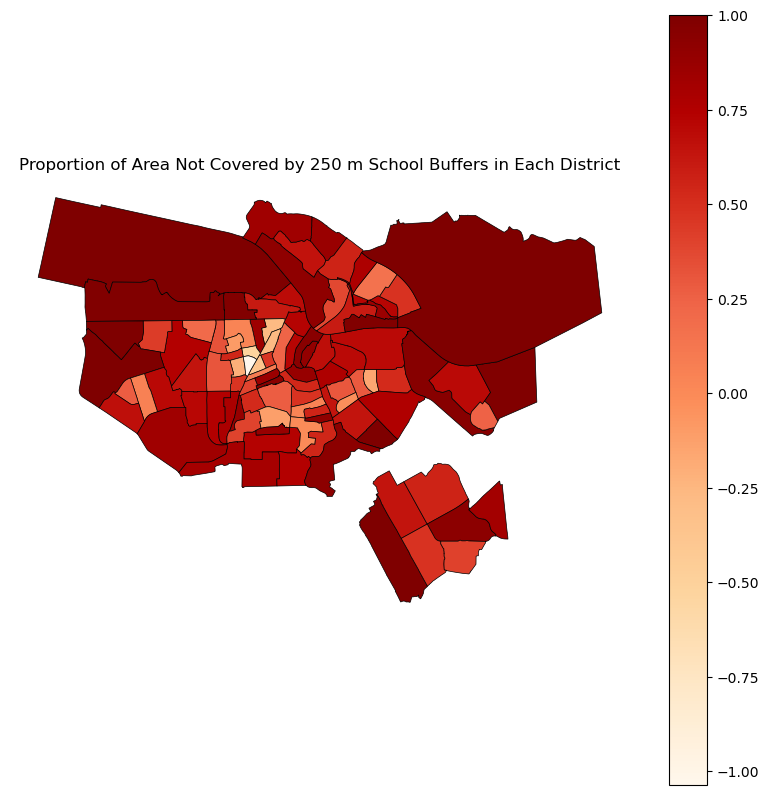

In [283]:
### Plot the results
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
districts.plot(
    ax=ax,
    column="proport_not_covered",
    legend=True,
    cmap="OrRd",
    edgecolor="black",
    linewidth=0.5,
)
plt.title("Proportion of Area Not Covered by 250 m School Buffers in Each District")
ax.axis("off")
plt.show()

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
Do you notice something weird here? If you run the above code without modification, you will obtain <b>negative proportions</b>. Negative proportions indicate that the sum of buffered area might have been larger than the total sum of area for some districts. This is of course impossible, and thus an invalid result. The reason lies in overlapping buffers. Thus, you need to correct the area calculation above.
</div>
<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
<h4> Assignment lab 2.1: </h4>
To correct this error, you need to turn the layer of overlapping buffers into a non-overlapping one by dissolving buffers (see  <a href="https://geopandas.org/en/stable/docs/user_guide/aggregation_with_dissolve.html">https://geopandas.org/en/stable/docs/user_guide/aggregation_with_dissolve.html</a>). Since you need to dissolve all buffers into a single multi-polygon, you can simply introduce a new attribute column with constant value, and then group by this attribute using the dissolve function. Check whether your resulting buffer layer indeed is non-overlapping (using explore()), and feed this new dataframe into the existing coverage calculations above. To pass this assignment, you need to:
<ol>
<li> submit valid numerical result and a corresponding choropleth map of the intended area not covered by schools, by correcting the conceptual error in the code (see above).</li>
<li> redo the analysis with one other appropriate point data layer, to be selected from a known Amsterdam geo-repository (see lab 1). Shortly describe the layer, and submit the numerical result together with the choropleth map. </li> 
</ol>
<div>


In [284]:
intersection_dissolved = gpd.overlay(districts, buffers_dissolved, how = "intersection")
intersection_dissolved.explore()

In [286]:
# Calculate area of intersection
intersection_dissolved["area_covered"] = intersection_dissolved.area

# Group by district ID and sum the covered areas
area_covered_by_district = (
    intersection_dissolved.groupby("Buurtcombinatie")["area_covered"].sum().reset_index()
)

# Merge the covered area data back to the original district data
districts = districts.merge(area_covered_by_district, on="Buurtcombinatie", how="left")

# Replace NaN values with 0 (for districts with no school coverage)
districts["area_covered"] = districts["area_covered"].fillna(0)

# Calculate total area of each district
districts["total_area"] = districts.area

# Calculate area not covered by school buffers, also calculate the proportion of this area
districts["area_not_covered"] = districts["total_area"] - districts["area_covered"]
districts["proport_not_covered"] = districts["area_not_covered"]/districts["total_area"]

# Display the results
print(districts[["Buurtcombinatie", "total_area", "area_covered", "area_not_covered"]])

            Buurtcombinatie    total_area   area_covered  area_not_covered
0     Burgwallen-Oude Zijde  4.047169e+05   40398.394038      3.643185e+05
1   Burgwallen-Nieuwe Zijde  7.283908e+05   38245.159992      6.901457e+05
2       Grachtengordel-West  5.690387e+05  160536.519433      4.085022e+05
3       Grachtengordel-Zuid  6.418352e+05   78137.429237      5.636977e+05
4        Nieuwmarkt/Lastage  1.066759e+06  316407.461098      7.503518e+05
..                      ...           ...            ...               ...
94     Bijlmer Oost (E,G,K)  4.075905e+06  830309.745660      3.245595e+06
95               Nellestein  2.948612e+06  188421.544934      2.760191e+06
96   Holendrecht/Reigersbos  2.712447e+06  612587.912538      2.099859e+06
97                     Gein  1.921408e+06  616179.927923      1.305229e+06
98                 Driemond  2.023220e+06  196794.621768      1.826426e+06

[99 rows x 4 columns]


In [287]:
### Summarize the total area, covered area, and not covered area for all districts
m_km = 10000000
total_area = districts["total_area"].sum() / m_km
total_covered_area = districts["area_covered"].sum() / m_km
total_not_covered_area = districts["area_not_covered"].sum() / m_km

print("\nSummary for All Districts:")
print(f"Total area: {total_area:.2f} km²")
print(f"Covered area: {total_covered_area:.2f} km²")
print(f"Not covered area: {total_not_covered_area:.2f} km²")


Summary for All Districts:
Total area: 21.95 km²
Covered area: 3.28 km²
Not covered area: 18.67 km²


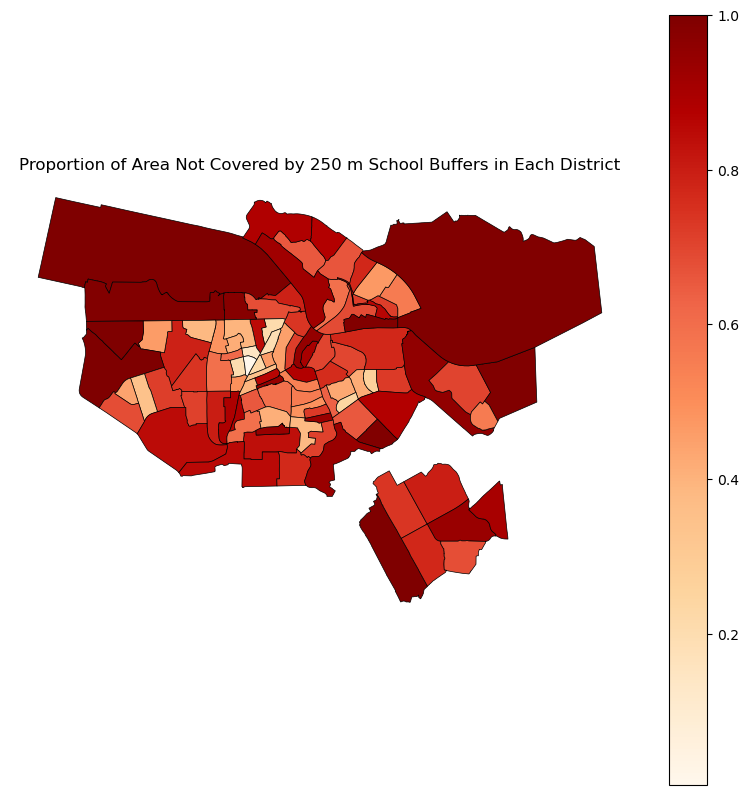

In [288]:
### Plot the results
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
districts.plot(
    ax=ax,
    column="proport_not_covered",
    legend=True,
    cmap="OrRd",
    edgecolor="black",
    linewidth=0.5,
)
plt.title("Proportion of Area Not Covered by 250 m School Buffers in Each District")
ax.axis("off")
plt.show()

### Markten Data

In [289]:
url = "https://maps.amsterdam.nl/open_geodata/geojson_lnglat.php?KAARTLAAG=MARKTEN&THEMA=markten"
markten = gpd.read_file(url)
markten.explore()

In [290]:
type(markten)

geopandas.geodataframe.GeoDataFrame

In [291]:
# creating 500m buffers
markten_buffers = markten.copy().to_crs(epsg=28992)
markten_buffers["geometry"] = markten_buffers["geometry"].buffer(200)
markten_buffers = markten_buffers.dissolve()
markten_buffers.explore()

In [292]:
districts_m = gpd.read_file("data/Amsterdam_BAG.gpkg", layer="Wijken")
districts_m.head()

,Buurtcombinatie,geometry
0,Burgwallen-Oude Zijde,"POLYGON ((122046.196 487743.941, 122027.476 48..."
1,Burgwallen-Nieuwe Zijde,"POLYGON ((122263.577 488126.48, 122236.187 488..."
2,Grachtengordel-West,"POLYGON ((121417.912 487990.296, 121396.294 48..."
3,Grachtengordel-Zuid,"POLYGON ((122002.986 486210.4, 121922.053 4864..."
4,Nieuwmarkt/Lastage,"POLYGON ((122748.335 487295.676, 122747.075 48..."


In [293]:
intersection_markten = gpd.overlay(districts_m, markten_buffers, how = "intersection")
intersection_markten.explore()

In [294]:
intersection_markten.head()

,Buurtcombinatie,Locatie,Artikelen,SELECTIE,FILTER_DAG,Maandag,Dinsdag,Woensdag,Donderdag,Vrijdag,Zaterdag,Zondag,Dagen,Gemeente,Foto,Website,Meer_informatie,Plattegrond,Openstaande_plaatsen,geometry
0,Burgwallen-Oude Zijde,Waterlooplein,Kunst / Antiek en curiosa,KUNSTANTIEK,Ma|Di|Wo|Do|Vr|Za|,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,,Di - Do - Ma - Vr - Wo - Za,Ja,,,,Waterlooplein COVID plattegrond.pdf,,"MULTIPOLYGON (((121307.059 487043.046, 121311...."
1,Burgwallen-Nieuwe Zijde,Waterlooplein,Kunst / Antiek en curiosa,KUNSTANTIEK,Ma|Di|Wo|Do|Vr|Za|,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,,Di - Do - Ma - Vr - Wo - Za,Ja,,,,Waterlooplein COVID plattegrond.pdf,,"POLYGON ((121419.097 486713.263, 121400.845 48..."
2,Grachtengordel-West,Waterlooplein,Kunst / Antiek en curiosa,KUNSTANTIEK,Ma|Di|Wo|Do|Vr|Za|,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,,Di - Do - Ma - Vr - Wo - Za,Ja,,,,Waterlooplein COVID plattegrond.pdf,,"MULTIPOLYGON (((120886.494 487918.613, 120950...."
3,Grachtengordel-Zuid,Waterlooplein,Kunst / Antiek en curiosa,KUNSTANTIEK,Ma|Di|Wo|Do|Vr|Za|,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,,Di - Do - Ma - Vr - Wo - Za,Ja,,,,Waterlooplein COVID plattegrond.pdf,,"MULTIPOLYGON (((121465.561 486715.061, 121484...."
4,Nieuwmarkt/Lastage,Waterlooplein,Kunst / Antiek en curiosa,KUNSTANTIEK,Ma|Di|Wo|Do|Vr|Za|,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,09.00-17.00 uur,,Di - Do - Ma - Vr - Wo - Za,Ja,,,,Waterlooplein COVID plattegrond.pdf,,"MULTIPOLYGON (((121735.58 487123.479, 121772.8..."


In [295]:
# area of itersections
intersection['area_covered'] = intersection.area

# group by districts and sum 
area_covered_by_district = (
    intersection.groupby("Buurtcombinatie")['area_covered'].sum().reset_index()
)

In [296]:
# merge area covered to orignal district data
districts_m = districts_m.merge(area_covered_by_district, on = "Buurtcombinatie", how = 'left')

In [298]:
# replace NaN with 0
districts_m['area_covered'] = districts["area_covered"].fillna(0)

# calculate total area, area_not_covered by school buffers 
# and propotion of area not covered to total area
districts_m['total_area'] = districts.area
districts_m['area_not_covered'] = districts['total_area'] - districts['area_covered']
districts_m['prop_area_not_covered'] = districts["area_not_covered"] / districts['total_area']

print(districts_m)

            Buurtcombinatie  \
0     Burgwallen-Oude Zijde   
1   Burgwallen-Nieuwe Zijde   
2       Grachtengordel-West   
3       Grachtengordel-Zuid   
4        Nieuwmarkt/Lastage   
..                      ...   
94     Bijlmer Oost (E,G,K)   
95               Nellestein   
96   Holendrecht/Reigersbos   
97                     Gein   
98                 Driemond   

                                             geometry   area_covered  \
0   POLYGON ((122046.196 487743.941, 122027.476 48...   40398.394038   
1   POLYGON ((122263.577 488126.48, 122236.187 488...   38245.159992   
2   POLYGON ((121417.912 487990.296, 121396.294 48...  160536.519433   
3   POLYGON ((122002.986 486210.4, 121922.053 4864...   78137.429237   
4   POLYGON ((122748.335 487295.676, 122747.075 48...  316407.461098   
..                                                ...            ...   
94  POLYGON ((128387.503 481146.961, 128379.732 48...  830309.745660   
95  POLYGON ((129550.279 479649.437, 129514.193 47.

In [299]:
### Summarize the total area, covered area, and not covered area for all districts
m_km = 10000000
total_area = districts_m["total_area"].sum() / m_km
total_covered_area = districts_m["area_covered"].sum() / m_km
total_not_covered_area = districts_m["area_not_covered"].sum() / m_km

print("\nSummary for All Districts:")
print(f"Total area: {total_area:.2f} km²")
print(f"Covered area: {total_covered_area:.2f} km²")
print(f"Not covered area: {total_not_covered_area:.2f} km²")


Summary for All Districts:
Total area: 21.95 km²
Covered area: 3.28 km²
Not covered area: 18.67 km²


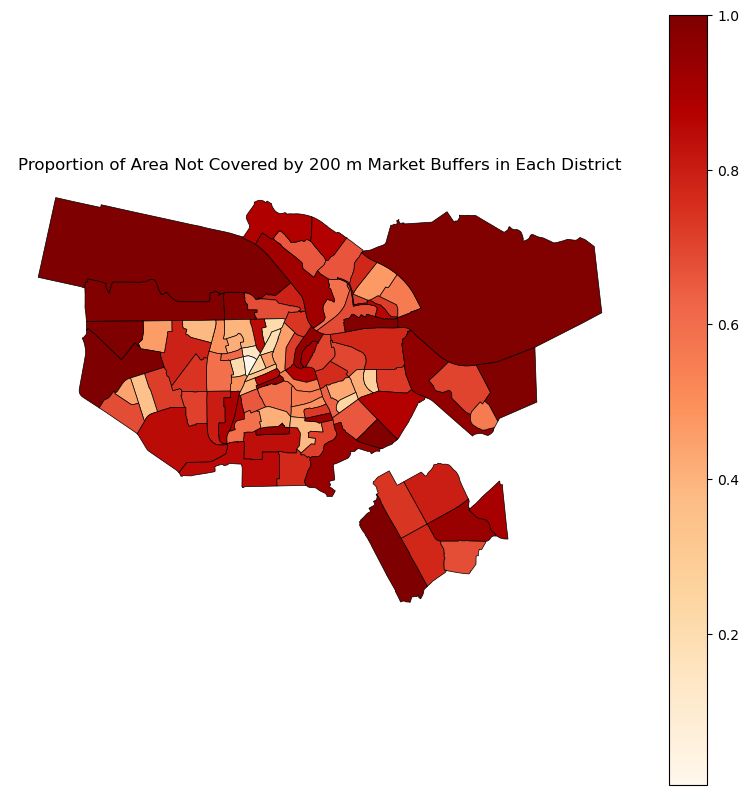

In [301]:
### Plot the results
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
districts.plot(
    ax=ax,
    column="proport_not_covered",
    legend=True,
    cmap="OrRd",
    edgecolor="black",
    linewidth=0.5,
)
plt.title("Proportion of Area Not Covered by 200 m Market Buffers in Each District")
ax.axis("off")
plt.show()

### Section 2: Vector areal interpolation
In this lab section, your task will be to determine the percentage of inhabitants which are older than 65 years for each postcode 4 (PC4) administrative unit in Amsterdam. The goal is to assess to what extent a given PC4 area hosts elderly people. The Centraal Bureau voor de Statistiek (CBS) openly publishes such data, however only on the level of Wijken en Buurten (Kerncijfers Wijken en buurten). The geodata file “CBS_Buurt_2014_AP_RDNew.shp” contains this information for the year 2014. Thus your task will be to interpolate these areal statistics from CBS units to PC4 units.

#### Import data sets and explore them in Folium
We start by importanting and exploring a CBS district layer and a postcode area layer.

In [302]:
# CBS
cbs_districts = gpd.read_file("data/CBS_Buurt_2014_AP_RDNew.shp")
print(cbs_districts.crs)
# PC4
PC4_districts = gpd.read_file("data/PC4.shp")
print(PC4_districts.crs)

EPSG:28992
EPSG:28992


In [303]:
### Create a folium map
# Center it around the average coordinates of the districts. Then overlay both layers and add a layer control:
m = cbs_districts.explore(
    style_kwds={"color": "black", "fill": False, "weight": 1}, name="CBS districts"
)
m = PC4_districts.explore(
    m=m,
    style_kwds={"color": "green", "fill": False, "weight": 0.8, "opacity": 0.8},
    name="PC4 districts",
)
# Add layer control to toggle the layers on and off
folium.LayerControl(collapsed=False).add_to(m)
m


what you can see here is that the two lattice layers, the postcode 4 (PC4) areas and the CBS districts, are not aligned regarding their spatial units. This means if you want to use postcode areas as spatial units for CBS statistics, you need to interpolate its attribute values. Looking at their attributes, we find a single statistics attribute in the CBS source. Let's first remove all missing values from the CBS data:

In [304]:
### Explore CBS dataset
# Check column names
print(cbs_districts.columns)
# Column for people 65 years old
print(cbs_districts["P_65_EO_JR"])
# Remove missing values
cbs_districts["P_65_EO_JR"] = cbs_districts["P_65_EO_JR"].clip(lower=0)

Index(['BU_CODE', 'BU_NAAM', 'WK_CODE', 'GM_CODE', 'GM_NAAM', 'WATER',
       'AANT_INW', 'AANT_MAN', 'AANT_VROUW', 'P_00_14_JR', 'P_15_24_JR',
       'P_25_44_JR', 'P_45_64_JR', 'P_65_EO_JR', 'P_ONGEHUWD', 'P_GEHUWD',
       'P_GESCHEID', 'P_VERWEDUW', 'BEV_DICHTH', 'AANTAL_HH', 'P_EENP_HH',
       'P_HH_Z_K', 'P_HH_M_K', 'GEM_HH_GR', 'P_WEST_AL', 'P_N_W_AL',
       'P_MAROKKO', 'P_ANT_ARU', 'P_SURINAM', 'P_TURKIJE', 'P_OVER_NW',
       'AUTO_TOT', 'AUTO_HH', 'AUTO_LAND', 'BEDR_AUTO', 'MOTOR_2W', 'A_LFTJ6J',
       'A_LFTO6J', 'A_BST_B', 'A_BST_NB', 'OPP_TOT', 'OPP_LAND', 'OPP_WATER',
       'geometry'],
      dtype='object')
0            8
1            7
2           15
3           14
4           13
        ...   
94          14
95          10
96          16
97          19
98   -99999998
Name: P_65_EO_JR, Length: 99, dtype: int64


#### Building an area interpolation function
In this part, we define a Python function that can be reused to calculate areal interpolations in a simplistic manner. This problem is called area interpolation in GIS. Conceptually it is a function that generates a *statistical lattice* from another one using polygon tessellations. 
There are sophisticated tools for this purpose in QGIS . However, for the sake of simplicity, you will implement the following interpolation technique in terms of Overlay tools, which computes the new statistics as an area-weighted average as shown below:

 ![arealInterp.png](arealInterp.png)

The following code generates an area weighted sum of source attribute values within each target geometry, normalized by the target area. Remember that a weighted sum is defined as: SUM(wv)/SUM(w), w = weights and v = values, where weights are area measurements in our case. In the case of areal interpolation, the weights are defined by the areas of intersected source polygon parts inside a given target polygon, and the values are the attribute values of the source polygons.

First, we (1) define the source and target geodataframes and the columns containing the target attribute and areas. Next, we (2) use an overlay function (geometric intersection) to compute the parts of the CBS districts (the source geometries) that geometrically intersect with a target geometry. Then we (3) compute an area weighted sum of the attribute values of source polygon parts for each target polygon. Finally, we (4) join/merge the resulting dataframe to the target geodatafame

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
Note that in the code of the areal interpolation function, the function (<code>area_weighted_sum</code>) used in step 2 is left blank. <b>You need to add a corresponding function</b>, to be entered in the code cell below this text. It should take a dataframe `intersection` and computes an area weighted sum of intersected polygon attribute values for each target polygon, using geopandas functions such as <code>groupby</code>. You can use the geopandas function <code> .geometry.area</code> to get an area measure of each geodataframe polygon, and you can apply arithmetic functions in the usual way (accounting for missing values). The resulting dataframe (<code>aggregated</code>) should have <code>target_area_id</code> (the id of each target polygon) as key attribute and the newly computed <code>weighted_attribute_sum</code> as dependent attribute. 
</div>

In [305]:
### Interpolate attribute values from source areas to target areas using area interpolation.

# Setp 1: Define GeoDataFrames and column names to be spatially interpolated
source_gdf = cbs_districts # (GeoDataFrame): GeoDataFrame with source areas.
target_gdf = PC4_districts # (GeoDataFrame): GeoDataFrame with target areas.
attribute = "P_65_EO_JR" # (str): The column name in source_gdf that contains the attribute to be interpolated.
target_area_id = "Postcode4" # (str): The column name in target_gdf that uniquely identifies each target area.

# Step 2: Overlay - geometric intersection of source and target geometries
intersection = gpd.overlay(source_gdf, target_gdf, how="intersection")

In [306]:
def area_weighted_sum(intersection: gpd.GeoDataFrame, attribute: str,
                      target_area_id: str) -> pd.DataFrame:
    '''
     Compute an area weighted sum of the target attribute for every unique
     target area in the intersection GeoDataFrame. The output DataFrame should
     contain two columns: the target area ID and the interpolated attribute value.
    '''
    intersection["area"] = intersection.geometry.area
    aggregate = intersection.groupby(target_area_id)["area"].sum().reset_index()

    return aggregate

In [307]:
# Step 3: Compute the area weighted sum of the target attribute
aggregated = area_weighted_sum(intersection, attribute, target_area_id)
aggregated

,Postcode4,area
0,0000,4.364414e+06
1,1011,1.062936e+06
2,1012,1.135797e+06
3,1013,5.297135e+06
4,1014,2.487438e+06
...,...,...
76,1104,2.034104e+06
77,1106,2.576045e+06
78,1107,1.817501e+06
79,1108,2.908040e+06


In [308]:
# Step 4: Join the interpolated values into the target_gdf
interpolated_gdf = pd.merge(
    target_gdf, aggregated, on = target_area_id
)

interpolated_gdf # (GeoDataFrame): The target_gdf with an additional column for the interpolated attribute.

,Postcode4,Opp_m2,FID_1,geometry,area
0,1037,1467857,1,"POLYGON ((118841.959 492112.126, 119075.212 49...",1.441803e+06
1,1041,3286912,2,"POLYGON ((116916.711 492585.123, 116976.001 49...",3.285911e+06
2,1073,588271,3,"POLYGON ((121299.599 485595.377, 121651.645 48...",5.880700e+05
3,1074,431143,4,"POLYGON ((121733.983 485576.298, 121899.799 48...",4.310346e+05
4,1072,595621,5,"POLYGON ((120928.002 485818.993, 120946.35 485...",5.953820e+05
...,...,...,...,...,...
76,1022,1388205,77,"MULTIPOLYGON (((123050.058 489088.152, 123089....",1.387820e+06
77,1036,272259,78,"POLYGON ((122140.454 491392.783, 122201.769 49...",2.721499e+05
78,1033,3826615,79,"POLYGON ((119353.041 491801.445, 119637.956 49...",3.825494e+06
79,1042,3671105,80,"POLYGON ((115709.229 492843.823, 116684.764 49...",3.670049e+06


#### Show resulting choropleth maps

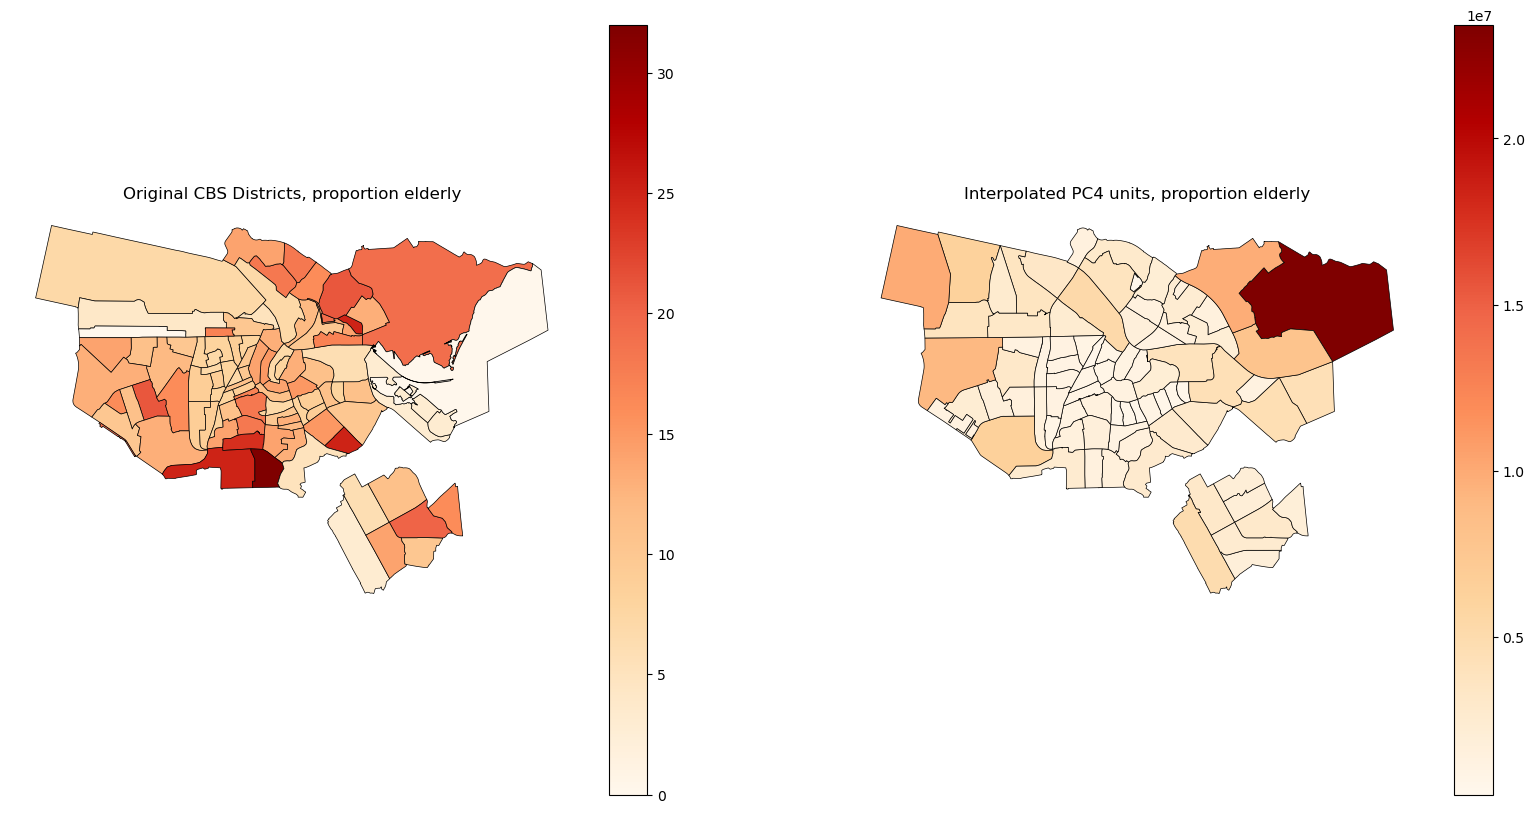

In [309]:
### Plot both maps side by side
# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Plot the original CBS districts
cbs_districts.plot(
    ax=axes[0],
    column="P_65_EO_JR",
    cmap="OrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
)
axes[0].set_title("Original CBS Districts, proportion elderly")
axes[0].axis("off")

# Plot the interpolated GeoDataFrame
interpolated_gdf.plot(
    ax=axes[1],
    column="area",
    cmap="OrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
)
axes[1].set_title("Interpolated PC4 units, proportion elderly")
axes[1].axis("off")

# Show the plots
plt.show()

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
<h4> Assignment 2.2: </h4>
<ol>
<li> Add the missing code to complete the areal interpolation function </li>
<li> Redo the above analysis with a different kind of lattice statistics data set. For submitting the assignment, describe the new data set and the resulting interpolated target maps.</li>
</ol>
</div>

In [311]:
cbs_districts

,BU_CODE,BU_NAAM,WK_CODE,GM_CODE,GM_NAAM,WATER,AANT_INW,AANT_MAN,AANT_VROUW,P_00_14_JR,...,BEDR_AUTO,MOTOR_2W,A_LFTJ6J,A_LFTO6J,A_BST_B,A_BST_NB,OPP_TOT,OPP_LAND,OPP_WATER,geometry
0,BU03630000,Burgwallen-Oude Zijde,WK036300,GM0363,Amsterdam,NEE,4190,2305,1885,6,...,110,120,195,535,575,150,41,35,6,"POLYGON ((121510.434 486739.724, 121493.751 48..."
1,BU03630001,Burgwallen-Nieuwe Zijde,WK036300,GM0363,Amsterdam,NEE,4470,2490,1980,5,...,120,125,350,550,685,210,75,61,14,"POLYGON ((121744.658 488409.813, 121897.063 48..."
2,BU03630002,Grachtengordel-West,WK036300,GM0363,Amsterdam,NEE,6995,3730,3265,9,...,155,170,685,1600,1840,445,64,50,14,"POLYGON ((121037.305 488186.624, 121158.635 48..."
3,BU03630003,Grachtengordel-Zuid,WK036300,GM0363,Amsterdam,NEE,4405,2335,2065,11,...,100,140,435,930,1100,265,52,42,10,"POLYGON ((121537.696 486730.716, 121689.33 486..."
4,BU03630004,Nieuwmarkt/Lastage,WK036300,GM0363,Amsterdam,NEE,9410,4910,4500,9,...,215,255,605,1355,1465,490,108,71,37,"POLYGON ((122222.222 488108.907, 122574.226 48..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,BU03630796,Holendrecht/Reigersbos,WK036307,GM0363,Amsterdam,NEE,18245,8530,9715,19,...,240,230,1185,3530,4080,635,269,260,9,"POLYGON ((125553.019 479482.01, 126033.55 4797..."
95,BU03630797,Gein,WK036307,GM0363,Amsterdam,NEE,11575,5645,5930,16,...,170,255,1075,2475,3035,515,191,185,7,"POLYGON ((129123.144 479344.606, 129121.313 47..."
96,BU03630798,Driemond,WK036307,GM0363,Amsterdam,NEE,1495,725,770,18,...,70,55,225,450,595,80,201,180,21,"POLYGON ((129702.519 481905.824, 129705.363 48..."
97,BU03940562,Badhoevedorp Dijk,WK039405,GM0394,Haarlemmermeer,NEE,455,230,220,17,...,40,20,70,170,200,40,15,10,5,"POLYGON ((113132.039 484676.338, 113151.874 48..."


In [313]:
migrants_df = pd.read_csv("data/migrants.csv")
migrants_df

,Gemeente,Totaal (% van de bevolking),Geboren buiten Nederland (% van de bevolking),Geboren in Nederland (% van de bevolking)
0,Aa en Hunze,"9,3","5,4","3,9"
1,Aalsmeer,"26,7","16,7","10,0"
2,Aalten,"12,9","6,5","6,3"
3,Achtkarspelen,"6,0","3,6","2,3"
4,Alblasserdam,"17,9","9,7","8,3"
...,...,...,...,...
337,Zundert,"18,2","11,0","7,1"
338,Zutphen,"19,9","9,9","10,0"
339,Zwartewaterland,"8,8","5,9","2,9"
340,Zwijndrecht,"26,9","13,7","13,2"


### Zonal map algebra of park density
Your task will be to aggregate land use data into PC4 areas in order to determine the coverage of these areas with parks and green and thus whether they are suitable for older people who would like to take a walk in the park. The Amsterdam Data Lab publishes high resolution data on land use in terms of vector polygons with an associated land use attribute (https://maps.amsterdam.nl/grondgebruik/?LANG=en).

![landuse.png](landuse.png)



Your task is to compute the area of parks and green areas within each PC4 region. This can be done by applying several raster analysis tools from map algebra to the data as explained in the following.

#### Data sources
Load the landuse dataset, check its attribute code and make it numeric.


In [ ]:
# Landuse
landuse_data = gpd.read_file("data/GRONDGEBRUIK_2017_RDNew.shp")
# Ensure 'land_use_id' is numeric
type_column = "CBScode2"
landuse_data[type_column] = pd.to_numeric(landuse_data[type_column], errors="coerce")

#### Define aggregation function that uses zonal map algebra 
This function should aggregate a landuse coverage into a statistical (vector) lattice. For this purpose, we first 
- generate a landuse raster from a vector landuse coverage 
- then turn it into a binary raster using a particular landuse value
- then sum that raster into each polygon of the lattice using zonal map algebra (to measure the number of pixels covered by that landuse)
- finally, we compute the area proportion of this landuse for each lattice polygon

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
This <b>last step is left out and needs to be added by you</b> into the following cell. To fill this gap, you need to define a function that takes a geodataframe of the vector lattice with pixel count attribute (<code>green_area_cells</code>), first computes the area of each polygon, and then the area proportion covered by pixels (Taking into account pixel sizes). Write the proportion into a new attribute <code>green_area</code> and return the dataframe.
</div>

In [ ]:
def area_proportion(stats, size, targetattr="green_area", pixelcount="green_area_cells"):







In [ ]:
def rasterize_and_analyze_landuse(landuse, sum_areas, attribute, pixel_size, green_area_id):
    """
    Rasterizes land use data, converts specific a land use class to binary raster,
    and calculates zonal statistics within provided polygons.

    Parameters:
    - landuse: GeoDataFrame with land use geometries and attributes.
    - sum_areas: GeoDataFrame with polygons for zonal statistics.
    - attribute: String, column name containing the landuse values.
    - pixel_size: Integer, size of the raster cells in meters.
    - green_area_id: Integer, land use class to be considered green area.

    Returns:
    - GeoDataFrame with zonal statistics and green area calculations.
    """
    
    # Step 1: Define raster properties
    xmin, ymin, xmax, ymax = landuse.total_bounds
    width = int((xmax - xmin) / pixel_size)
    height = int((ymax - ymin) / pixel_size)
    transform = from_origin(xmin, ymax, pixel_size, pixel_size)
    
    # Step 2: Create an empty raster
    out_shape = (height, width)
   
    # Step 3: Convert the land use vector layer into a binary raster 
    landuse_shapes = (
        (geom, value) for geom, value in zip(landuse.geometry, landuse[attribute])
    )
    burned = features.rasterize(
        landuse_shapes, out_shape=out_shape, transform=transform, fill=0, dtype=np.uint8
    )
    
    # Step 4: Convert specific land use class into binary raster
    green_areas_raster = np.where(burned == green_area_id, 1, 0)
    
    # Step 5: Plot the raster
    fig, ax = plt.subplots(figsize=(10, 10))
    show(green_areas_raster, ax=ax, title="Green Areas Raster")
    plt.show()
    
    # Step 6: Calculate zonal statistics
    zs = rs.zonal_stats(
        sum_areas,
        green_areas_raster,
        affine=transform,
        stats="sum",
        nodata=0,
        geojson_out=True,
    )
    
    # Step 7: Convert the result to a GeoDataFrame
    zonal_stats = gpd.GeoDataFrame.from_features(zs)
    zonal_stats.rename(columns={"sum": "green_area_cells"}, inplace=True)
    
    #Step 8: compute area proportions covered by landuse
    zonal_stats =  area_proportion(zonal_stats, pixel_size, targetattr="green_area", pixelcount="green_area_cells")
    
    return zonal_stats

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">
<h4>Apply aggregation function to landuse "park"</h4>
In this step, you should apply the function to aggregate "park" landuse within PC4 districts. First, you need to find out the landuse class value (ID) used to denote parks. This can be done by taking a look at the <code>landuse_data</code> table attributes, where land use classes are given in the attribute <code>CBScode2</code> and their textual descriptions in <code>CBScode2_O</code>. Then run the aggregation using this value and a 50 meter raster cell size for this purpose. You also need a reference to the PC4 lattice data. Figure out how this can be done on your own and <b>enter the code into the following cell</b> to genereate a dataframe <code>pc4_parks</code> which contains park density as an attribute:
</div>

In [ ]:

# Find landuse class value for park aggregation
print(set(landuse_data['CBScode2_O'].tolist()))
print(landuse_data.loc[landuse_data['CBScode2_O'] == 'Park en plantsoen', 'CBScode2']) 
id_green = 40
# Set the size of cell
pixel_s = 50
pc4_parks = rasterize_and_analyze_landuse(landuse_data, PC4_districts, type_column, pixel_s, id_green)

Finally print the resulting map of "pc4_parks":

In [ ]:
### Plot new map
# Create subplots
fig, ax = plt.subplots(1, 1, figsize=(20, 10))

# Plot the interpolated GeoDataFrame
pc4_parks.plot(
    ax=ax,
    column="green_area",
    cmap="Greens",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
)
ax.set_title("Area proportion of park per PC4 area")
ax.axis("off")

# Show the plots
plt.show()

<div style="background-color: #E0FFFF; outline: black; color: black; padding: 10px;">

<h3> Assignment 2.3</h3>
<ol>
<li> Add the missing pieces of code to the code above to compute the percentage of green parks per PC4 area in Amsterdam</li>
<li> Redo this analysis for one other landuse type and document the results with maps</li>
</ol>
</div>